# Pertemuan 5 - Decision Tree (Breast Cancer)


In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

%matplotlib inline

In [20]:
# Load dataset: jika file belum ada di /content, minta upload otomatis
PATH = "/content/beast_cancer.csv"
if not os.path.exists(PATH):
    from google.colab import files
    up = files.upload()                 # pilih beast_cancer.csv
    PATH = list(up.keys())[0]

df = pd.read_csv(PATH)
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")   # aman jika kolom tidak ada
X = df.drop(columns="diagnosis")
y = (df["diagnosis"] == "M").astype(int)                       # M = 1 (ganas), B = 0 (jinak)

In [21]:
# Cek data (sebelumnya data.frame.info() -> error karena variabel `data` tidak ada)
df.info()
print("\nDistribusi kelas:\n", y.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [22]:
# Split train/test
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(Xtr.shape, Xte.shape)

(455, 30) (114, 30)


In [23]:
# Grid search manual dengan Stratified 5-Fold CV
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for d in [2, 4, 6, None]:
    for m in [1, 5, 10]:
        def mk(d=d, m=m):
            return DecisionTreeClassifier(max_depth=d, min_samples_leaf=m, random_state=42)
        r = cross_validate(mk(), Xtr, ytr, cv=cv, scoring="accuracy")
        t = mk().fit(Xtr, ytr)
        rows.append(dict(
            max_depth=str(d), min_samples_leaf=m,
            train_acc=accuracy_score(ytr, t.predict(Xtr)),
            cv_mean=r["test_score"].mean(), cv_std=r["test_score"].std(),
            leaf=t.get_n_leaves(), depth_real=t.get_depth(),
            test_acc=accuracy_score(yte, t.predict(Xte))))
res = pd.DataFrame(rows)

In [24]:
# Pemilihan model dengan aturan 1-SE (pilih pohon paling sederhana yang CV-nya setara terbaik)
best = res.loc[res.cv_mean.idxmax()]
se = best.cv_std / np.sqrt(5)
cand = res[res.cv_mean >= best.cv_mean - se]
pick = cand.sort_values(["leaf", "cv_mean"], ascending=[True, False]).iloc[0]

res["gap_train_cv"] = res.train_acc - res.cv_mean
res["gap_train_test"] = res.train_acc - res.test_acc

out = res.round(4)
out.to_csv("tabel_hasil.csv", index=False)
display(out)

pick_depth = None if pick.max_depth == "None" else int(pick.max_depth)
pick_msl = int(pick.min_samples_leaf)
print(f"CV terbaik : depth={best.max_depth}, msl={int(best.min_samples_leaf)}, CV={best.cv_mean:.4f}, SE={se:.4f}")
print(f"DIPILIH    : depth={pick.max_depth}, msl={pick_msl}")

final = DecisionTreeClassifier(max_depth=pick_depth, min_samples_leaf=pick_msl, random_state=42).fit(Xtr, ytr)
tr = accuracy_score(ytr, final.predict(Xtr))
te = accuracy_score(yte, final.predict(Xte))
print(f"FINAL train={tr:.4f} CV={pick.cv_mean:.4f} test={te:.4f} gap={tr-te:.4f} leaf={final.get_n_leaves()} depth={final.get_depth()}")

,max_depth,min_samples_leaf,train_acc,cv_mean,cv_std,leaf,depth_real,test_acc,gap_train_cv,gap_train_test
0,2,1,0.9538,0.9209,0.0245,4,2,0.9211,0.0330,0.0328
1,2,5,0.9538,0.9297,0.0237,4,2,0.9211,0.0242,0.0328
2,2,10,0.9473,0.9253,0.0254,4,2,0.9298,0.0220,0.0174
3,4,1,0.9824,0.9209,0.0383,13,4,0.9123,0.0615,0.0701
4,4,5,0.9626,0.9253,0.0306,9,4,0.9035,0.0374,0.0591
5,4,10,0.9582,0.9231,0.0260,8,4,0.9123,0.0352,0.0460
6,6,1,0.9934,0.9209,0.0389,19,6,0.9211,0.0725,0.0724
7,6,5,0.9626,0.9253,0.0306,12,6,0.9035,0.0374,0.0591
8,6,10,0.9582,0.9231,0.0260,10,6,0.9123,0.0352,0.0460
9,None,1,1.0000,0.9231,0.0326,24,8,0.9298,0.0769,0.0702


CV terbaik : depth=2, msl=5, CV=0.9297, SE=0.0106
DIPILIH    : depth=2, msl=5
FINAL train=0.9538 CV=0.9297 test=0.9211 gap=0.0328 leaf=4 depth=2


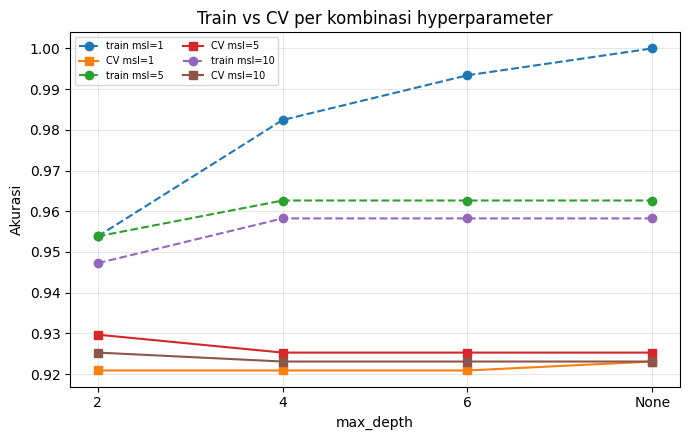

In [25]:
# Grafik train vs CV
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in [1, 5, 10]:
    s = res[res.min_samples_leaf == m]
    ax.plot(s.max_depth, s.train_acc, "o--", label=f"train msl={m}")
    ax.plot(s.max_depth, s.cv_mean, "s-", label=f"CV msl={m}")
ax.set_xlabel("max_depth"); ax.set_ylabel("Akurasi")
ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3)
ax.set_title("Train vs CV per kombinasi hyperparameter")
plt.tight_layout()
plt.savefig("grafik_train_vs_cv.png", dpi=150)
plt.show()

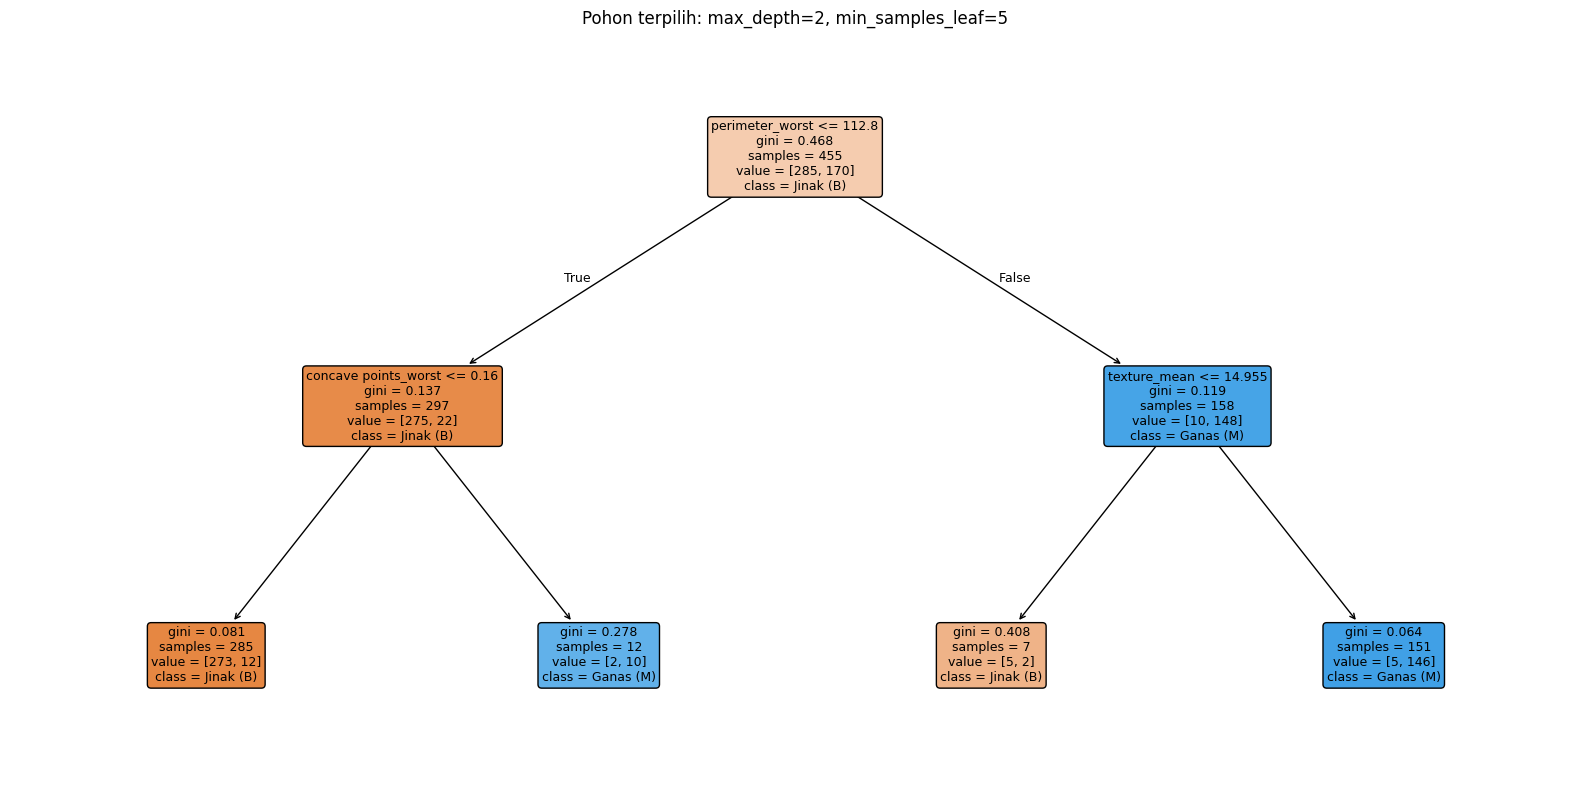

In [26]:
# Visualisasi pohon terpilih
plt.figure(figsize=(16, 8))
plot_tree(final, feature_names=list(X.columns), class_names=["Jinak (B)", "Ganas (M)"],
          filled=True, rounded=True, fontsize=9)
plt.title(f"Pohon terpilih: max_depth={pick.max_depth}, min_samples_leaf={pick_msl}")
plt.tight_layout()
plt.savefig("pohon_terpilih.png", dpi=150)
plt.show()

In [27]:
# (Opsional) unduh hasil ke komputer
from google.colab import files
for f in ["tabel_hasil.csv", "grafik_train_vs_cv.png", "pohon_terpilih.png"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>